# Regional Dependence of Power Grid Resilience

This notebook investigates how the **resilience of a high-voltage (HV) power grid** varies across a full year of operation, using [SimBench](https://simbench.de/en/) benchmark grids and [pandapower](https://www.pandapower.org/) for AC power flow simulation.

**Workflow:**
1. Load a SimBench HV grid and its yearly load/generation profiles.
2. Run a power flow for every snapshot in the period and extract resilience-relevant results (line loading, voltages, worst-case components).
3. Identify the grid's **System Reserve** (the least-used lines/buses) and **System Burden** (the most heavily-loaded lines/buses) across the whole period.
4. Analyse the grid's topology using graph theory (betweenness, closeness, eigenvector centrality) to identify structurally critical buses.


## 1. Setup
Import the packages needed for grid modelling, power flow, plotting and graph analysis.

In [1]:
# Import all the Functions required
from Functions import *

## 2. Load the SimBench Grid
Download/load a SimBench benchmark grid by its code and visualise its topology.

This pandapower network includes the following parameter tables:
   - bus (82 elements)
   - load (79 elements)
   - sgen (98 elements)
   - ext_grid (1 element)
   - line (113 elements)
   - trafo (3 elements)
   - measurement (431 elements)
   - substation (14 elements)
   - loadcases (6 elements)


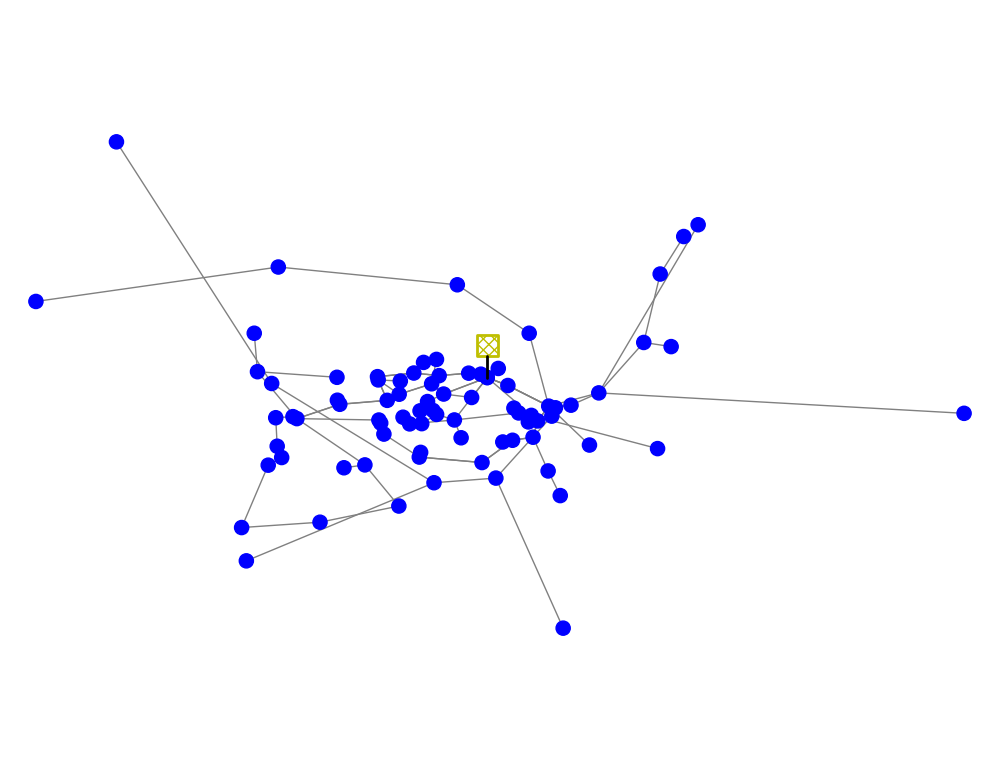

In [2]:
# SimBench grid code to analyse - see sb.collect_all_simbench_codes() for all available options
network = "1-HV-urban--0-no_sw" # "1-HVMV-urban-3.201-1-no_sw" and "1-HV-urban--0-no_sw"
id = 1

net_simbench = import_sb_grid(network)

## 3. Load and Generation Profiles
Extract the full-year time series of load and generation for the grid, and plot the total system profile at a chosen resolution.

Available profile keys:
  ('load', 'p_mw')                    shape=(35136, 79)
  ('load', 'q_mvar')                  shape=(35136, 79)
  ('sgen', 'p_mw')                    shape=(35136, 98)
  ('gen', 'p_mw')                     shape=(35136, 0)
  ('storage', 'p_mw')                 shape=(0, 0)


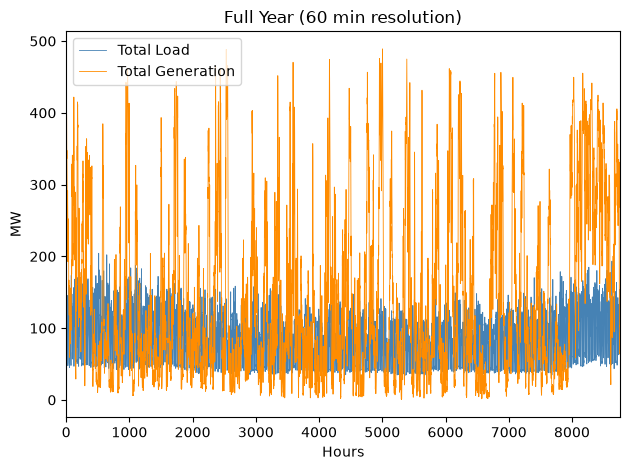

In [3]:
profiles = get_profiles(net_simbench, 4, id)

## 4. Time-Series Power Flow Simulation

For every snapshot in the profile period, the grid's loads/generation are updated and an AC power flow is solved. From each converged snapshot we extract:

- **Summary results** (worst line, worst bus, voltage limits) -> `snapshot_df`, used for the overview plot below.
- **Full per-line and per-bus loading history** -> `line_loading_history` / `bus_power_history`, used in Section 4.1 to find the System Reserve and System Burden.

  Progress: 0/8750 (t=0)
  Progress: 50/8750 (t=200)
  Progress: 100/8750 (t=400)
  Progress: 150/8750 (t=600)
  Progress: 200/8750 (t=800)
  Progress: 250/8750 (t=1000)
  Progress: 300/8750 (t=1200)
  Progress: 350/8750 (t=1400)
  Progress: 400/8750 (t=1600)
  Progress: 450/8750 (t=1800)
  Progress: 500/8750 (t=2000)
  Progress: 550/8750 (t=2200)
  Progress: 600/8750 (t=2400)
  Progress: 650/8750 (t=2600)
  Progress: 700/8750 (t=2800)
  Progress: 750/8750 (t=3000)
  Progress: 800/8750 (t=3200)
  Progress: 850/8750 (t=3400)
  Progress: 900/8750 (t=3600)
  Progress: 950/8750 (t=3800)
  Progress: 1000/8750 (t=4000)
  Progress: 1050/8750 (t=4200)
  Progress: 1100/8750 (t=4400)
  Progress: 1150/8750 (t=4600)
  Progress: 1200/8750 (t=4800)
  Progress: 1250/8750 (t=5000)
  Progress: 1300/8750 (t=5200)
  Progress: 1350/8750 (t=5400)
  Progress: 1400/8750 (t=5600)
  Progress: 1450/8750 (t=5800)
  Progress: 1500/8750 (t=6000)
  Progress: 1550/8750 (t=6200)
  Progress: 1600/8750 (t=6400)
  Progr

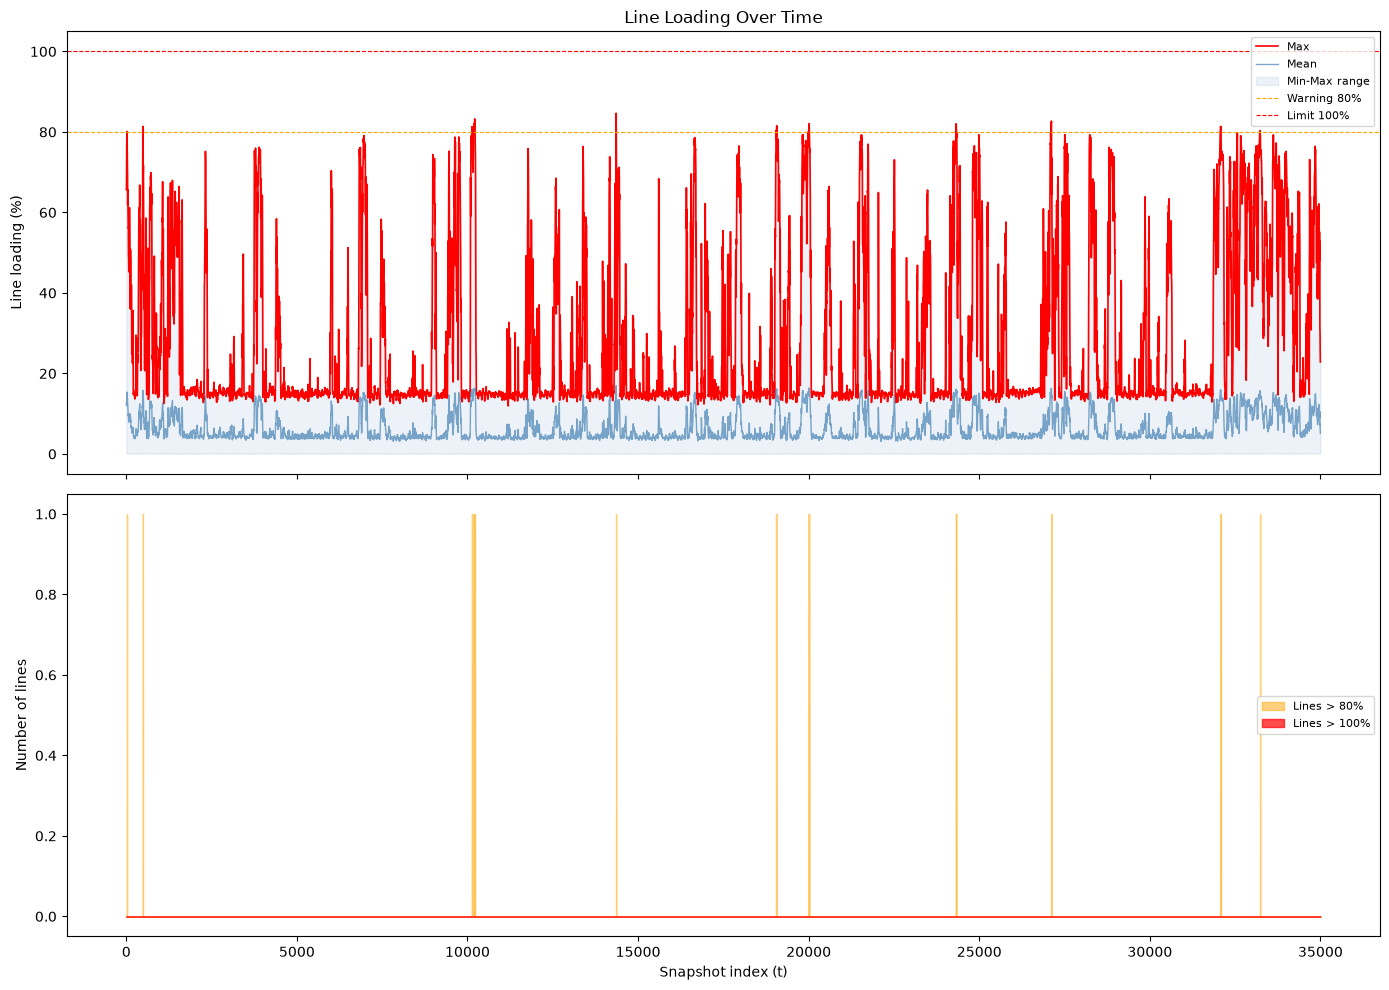

In [4]:
snapshot_df, line_loading_history, bus_power_history, bus_voltage_history = run_powerflow_over_period(net_simbench, profiles, id, 0, 35000, 4)
plot_line_loading_over_time(snapshot_df, id)

### 4.1 System Reserve and System Burden

These two indicators identify **which specific lines and buses** are under-used or over-used across the whole simulated period, using the full `line_loading_history` / `bus_power_history` collected above:

- **System Reserve** - the lines/buses that are **least used** across the whole period. They represent spare capacity in the grid: components that are rarely stressed and could take on more load if the network were reconfigured or reinforced elsewhere.
- **System Burden** - the lines/buses that are **highly loaded at times** across the period. They are the recurring bottlenecks - the components that should be reinforced/upgraded over time to keep the network healthy as demand grows.

In [14]:
reserve_lines, reserve_buses = find_system_reserve(line_loading_history, bus_voltage_history, net_simbench, top_n=10)
burden_lines, burden_buses = find_system_burden(line_loading_history, bus_voltage_history, net_simbench, top_n=10, v_band=(0.90, 1.10))

Top 10 most UNDER-USED lines (System Reserve):
  HV2 Line 45 (idx 44): mean loading = 0.12%  |  connects bus 109 <-> bus 208
  HV2 Line 36 (idx 35): mean loading = 0.12%  |  connects bus 233 <-> bus 358
  HV2 Line 32 (idx 31): mean loading = 0.12%  |  connects bus 156 <-> bus 240
  HV2 Line 29 (idx 28): mean loading = 0.13%  |  connects bus 11 <-> bus 50
  HV2 Line 1 (idx 0): mean loading = 0.18%  |  connects bus 27 <-> bus 176
  HV2 Line 49 (idx 48): mean loading = 0.44%  |  connects bus 123 <-> bus 210
  HV2 Line 97 (idx 96): mean loading = 0.48%  |  connects bus 199 <-> bus 94
  HV2 Line 90 (idx 89): mean loading = 0.64%  |  connects bus 27 <-> bus 179
  HV2 Line 63 (idx 62): mean loading = 0.69%  |  connects bus 134 <-> bus 220
  HV2 Line 22 (idx 21): mean loading = 0.78%  |  connects bus 65 <-> bus 216

Top 10 most STABLE buses (System Reserve, by voltage):
  EHV Bus 1865 (idx 0): mean |vm - 1.0| = 0.0680 pu  |  connected lines: []
  HV2 Bus 46 (idx 50): mean |vm - 1.0| = 0.0829 p

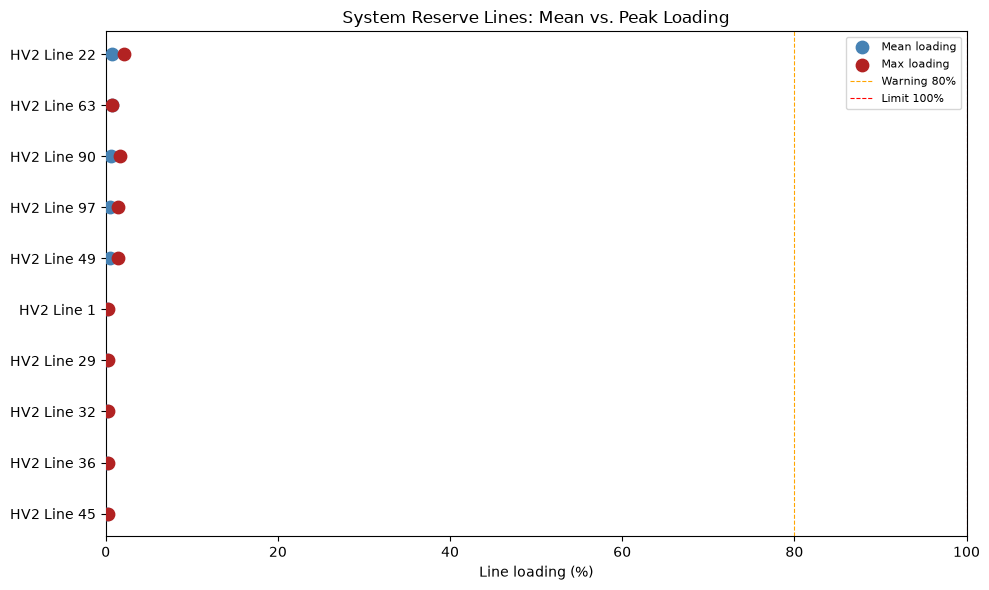

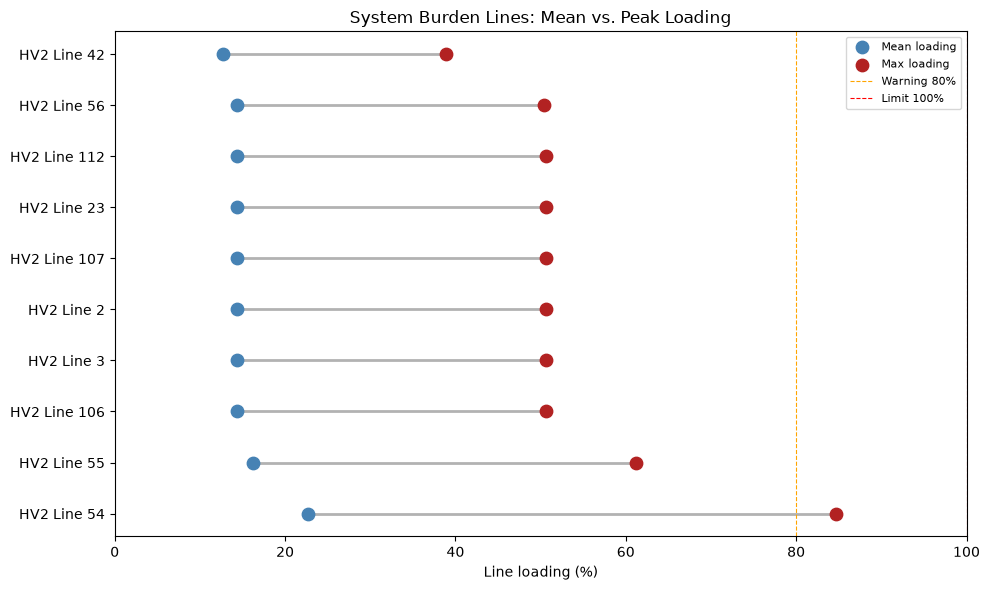

In [15]:
plot_mean_vs_max(reserve_lines.index, line_loading_history, net_simbench,
                  "System Reserve Lines: Mean vs. Peak Loading", "reserve_mean_vs_max", id)

plot_mean_vs_max(burden_lines.index, line_loading_history, net_simbench,
                  "System Burden Lines: Mean vs. Peak Loading", "burden_mean_vs_max", id)

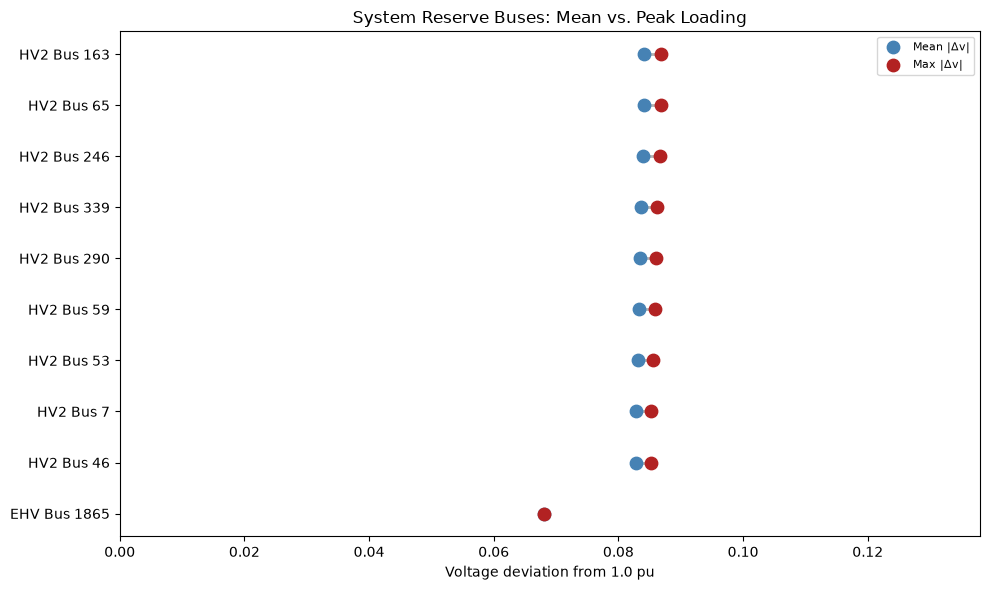

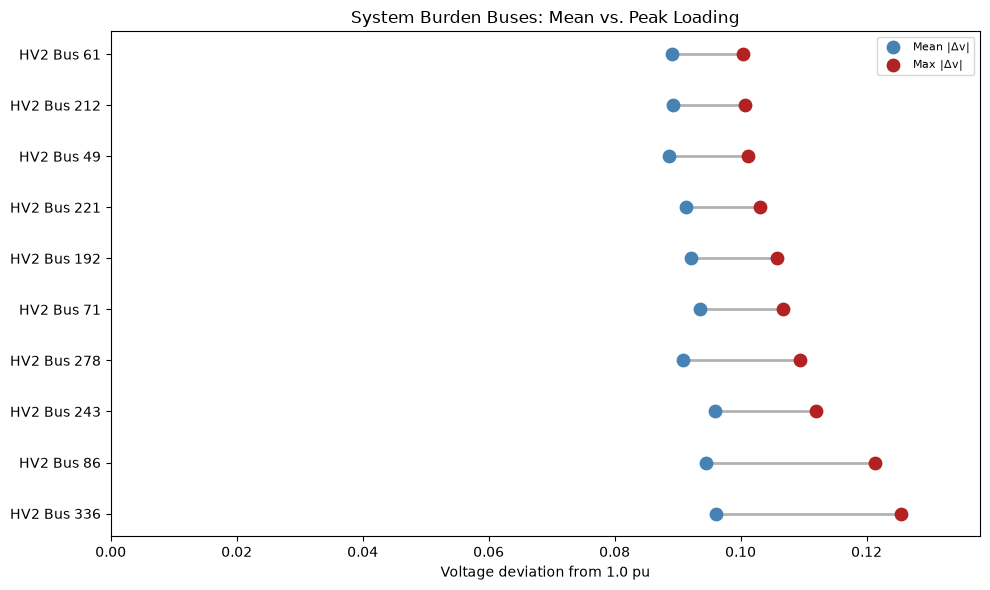

In [16]:
all_ids = list(reserve_buses.index) + list(burden_buses.index)
combined_dev = (bus_voltage_history[all_ids] - 1.0).abs()
x_max = combined_dev.values.max() * 1.1  # small padding so the rightmost dot isn't clipped

plot_voltage_deviation_mean_vs_max(reserve_buses.index, bus_voltage_history, net_simbench,
                                    "System Reserve Buses: Mean vs. Peak Loading", "reserve_mean_vs_max_buses", id,
                                    xlim=(0, x_max))

plot_voltage_deviation_mean_vs_max(burden_buses.index, bus_voltage_history, net_simbench,
                                    "System Burden Buses: Mean vs. Peak Loading", "burden_mean_vs_max_buses", id,
                                    xlim=(0, x_max))

## 5. Network Topology and Graph Construction

Beyond power flow, the grid's *topology* also determines resilience: some buses are structurally more critical than others regardless of loading. We extract the bus/line topology into a graph representation for this analysis.

In [17]:
nodes = get_node_list(net_simbench)
arcs = get_arc_list(net_simbench)

In [18]:
graph_simbench, layout = make_graph_net(nodes, arcs, id)

## 6. Centrality Analysis

Three classic centrality measures highlight structurally important buses:

- **Betweenness** - how often a bus lies on the shortest path between other buses (bridge/bottleneck role).
- **Closeness** - how quickly a bus can reach all other buses (average distance).
- **Eigenvector** - how well-connected a bus is to other well-connected buses (influence).

     NodeIndex        x        y  betweenness
0            0  9.82158  52.4249         0.00
5            5  9.74204  52.3670       132.50
11          11  9.82158  52.4249      1482.63
27          27  9.91718  52.2782        79.00
31          31  9.81336  52.2914       359.92
..         ...      ...      ...          ...
351        351  9.43580  52.1893        44.50
353        353  9.89085  52.3655       196.78
358        358  9.84601  52.3237         0.00
361        361  9.47757  52.2873         8.50
365        365  9.76995  52.3583       430.72

[82 rows x 4 columns]

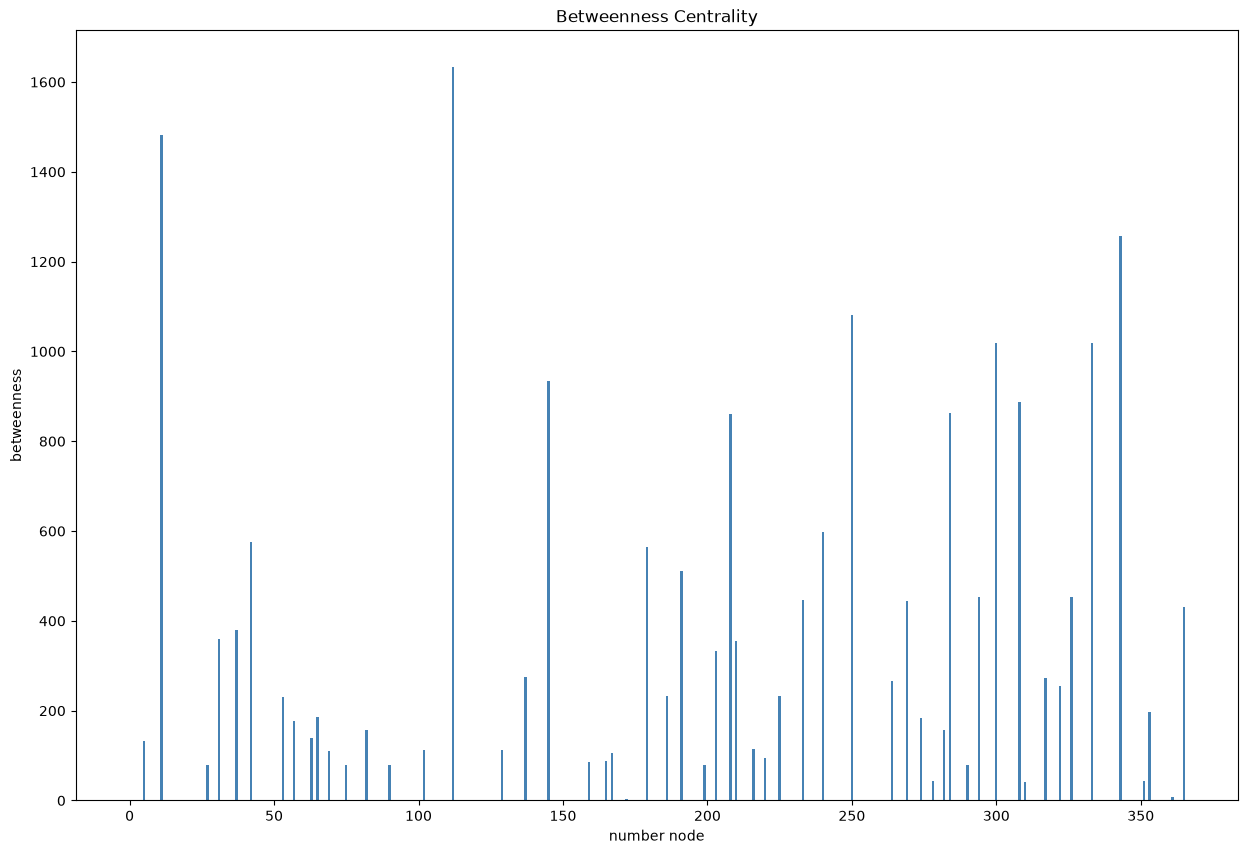

In [19]:
calculate_betweenness_centrality(graph_simbench, nodes, id)

     NodeIndex        x        y  betweenness  closeness
0            0  9.82158  52.4249         0.00        NaN
5            5  9.74204  52.3670       132.50       0.14
11          11  9.82158  52.4249      1482.63       0.19
27          27  9.91718  52.2782        79.00       0.14
31          31  9.81336  52.2914       359.92       0.15
..         ...      ...      ...          ...        ...
351        351  9.43580  52.1893        44.50       0.09
353        353  9.89085  52.3655       196.78       0.17
358        358  9.84601  52.3237         0.00       0.13
361        361  9.47757  52.2873         8.50       0.09
365        365  9.76995  52.3583       430.72       0.16

[82 rows x 5 columns]


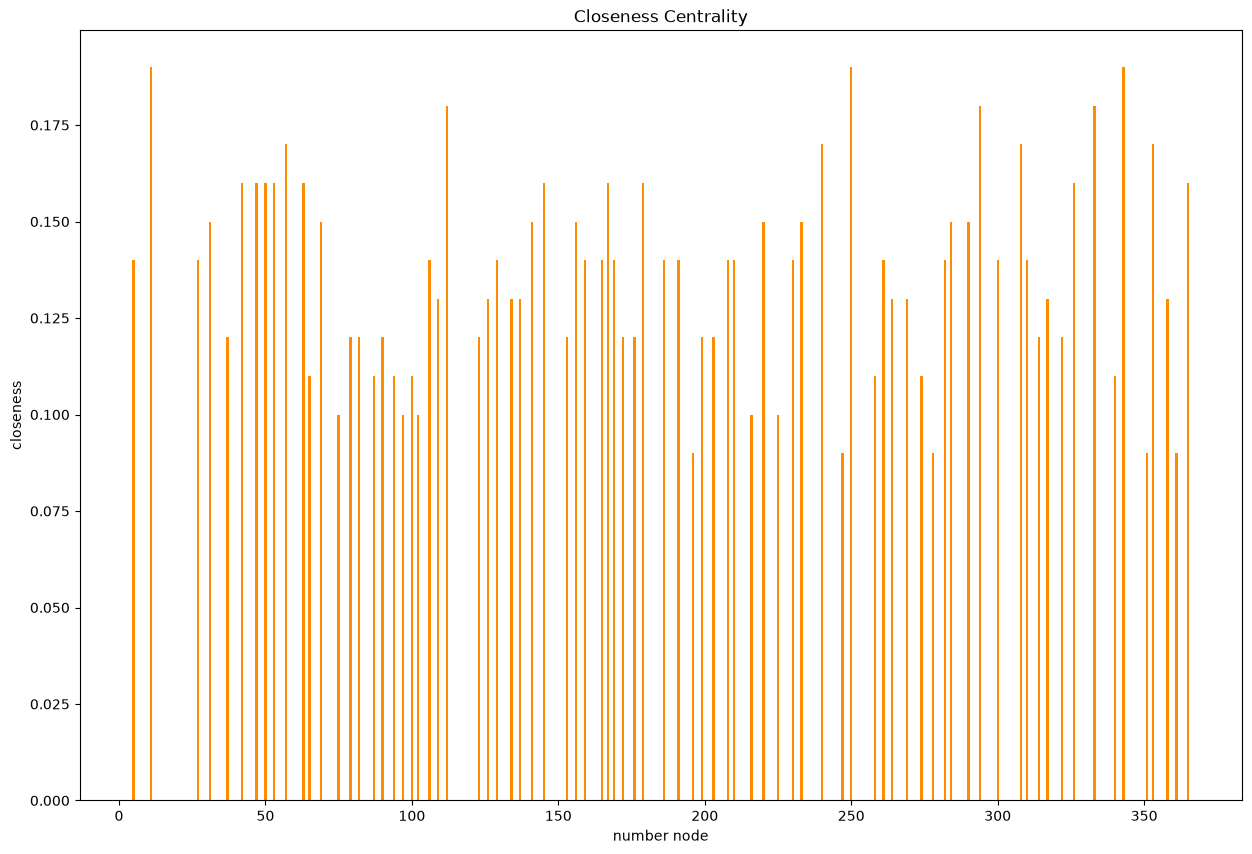

In [20]:
calculate_closeness_centrality(graph_simbench, nodes, id)

In [21]:
# Which buses are centrality "hubs"?
top_betweenness = nodes.set_index('NodeIndex')['betweenness'].nlargest(10).index
top_closeness = nodes.set_index('NodeIndex')['closeness'].nlargest(10).index

print("Top betweenness buses:", list(top_betweenness))
print("Top closeness buses:", list(top_closeness))

Top betweenness buses: [112, 11, 343, 250, 333, 300, 145, 308, 284, 208]
Top closeness buses: [11, 250, 343, 112, 294, 333, 57, 240, 308, 353]


In [ ]:
table = build_betweenness_loading_table(burden_lines, nodes, net_simbench, top_n_betweenness=10)
print(table.to_string(index=False))

n_connected = (table['Connects to Top-Betweenness Bus?'] == 'Yes').sum()
print(f"\n{n_connected} of {len(table)} highest-loaded lines connect directly to a top-betweenness bus.")

        Line  Peak Loading (%)  From Bus  From Bus Betweenness  To Bus  To Bus Betweenness Connects to Top-Betweenness Bus?
 HV2 Line 54             84.65        53                231.00     112              1633.1                              Yes
 HV2 Line 55             61.22        53                231.00     282               156.0                               No
HV2 Line 106             50.63       112               1633.10     343              1256.8                              Yes
  HV2 Line 3             50.63       112               1633.10     343              1256.8                              Yes
  HV2 Line 2             50.63       112               1633.10     343              1256.8                              Yes
HV2 Line 107             50.60        11               1482.63     343              1256.8                              Yes
 HV2 Line 23             50.60        11               1482.63     343              1256.8                              Yes
HV2 Line